# Copper 17-11 — Residual Ridge: 4 kiểm chứng độc lập

**Mục tiêu:** Kiểm chứng Ridge dự báo biến động giá đồng có thật sự tốt hơn Naive Persistence hay không, bằng (1) expanding walk-forward, (2) Diebold–Mariano/HAC, (3) Directional Accuracy và (4) ablation đầu vào.

**Dữ liệu huấn luyện lại từ CSV gốc, không dùng checkpoint/model cũ.** Mặc định dự đoán **Copper(t)** chỉ với thông tin sẵn có **đến cuối phiên t−1** (one-step ahead). Đây là thí nghiệm mở rộng, **không phải thuật toán SA-LSTM của bài báo**.

**Cách đọc kết quả:** Nếu MAE/RMSE thấp nhưng không có ý nghĩa thống kê hoặc DA thấp, không nên kết luận mô hình dự báo biến động tốt. Không so sánh `MSE_scaled` với `RMSE_raw`.

## 1. Cấu hình và thư viện

Không yêu cầu TensorFlow, GPU hay Internet. Trên Kaggle hãy attach `dataset_9_commodities_daily.csv` tương tự notebook V16. Có tùy chọn dùng bộ CSV Copper 8 indicators nếu không có bộ 9 commodities.

In [11]:
from pathlib import Path
from datetime import datetime, timezone
import json, zipfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import sklearn, scipy

CONFIG = {
    'lookback': 22,
    'first_test_date': '2018-01-01',  # train lần đầu 2016-2017 nếu đủ
    'minimum_train_samples': 350,
    'retrain_every_sessions': 21,  # 21 phiên ~ 1 tháng, không phải mỗi ngày
    'validation_fraction': 0.15,
    'ridge_alphas': [0.1, 1.0, 10.0, 100.0],
    'training_policy': 'expanding',  # 'expanding' hoặc 'rolling_756'
    'rolling_train_rows': 756,
    'dm_hac_lags': 5,  # robust với tự tương quan của loss differential
    'seed': 42,
}
np.random.seed(CONFIG['seed'])
OUT = Path('/kaggle/working/copper_ridge_backtest') if Path('/kaggle/working').exists() else Path('copper_ridge_backtest')
OUT.mkdir(parents=True, exist_ok=True)
print('Output:', OUT.resolve(), '| sklearn:', sklearn.__version__)

Output: /kaggle/working/copper_ridge_backtest | sklearn: 1.6.1


## 2. Đọc và kiểm tra dữ liệu

Dữ liệu chính là file 9 commodities của V16, từ 2016–2026 nếu còn đủ ngày. Không tự tải Yahoo Finance. Chỉ làm sạch trên `Date`, Copper, WTI, Gold, Silver để giữ nhiều quan sát phù hợp cho so sánh ba biến.

In [12]:
DATASET_CANDIDATES = [
    Path('/kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'),
    Path('/kaggle/input/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'),
    Path('data/processed/dataset_9_commodities_daily.csv'),
    Path('/kaggle/input/datasets/lancelot71000/copper-8-indicators-2006-2026/copper_8_indicators_2006_2026.csv'),
    Path('/kaggle/input/copper-8-indicators-2006-2026/copper_8_indicators_2006_2026.csv'),
]
DATA_PATH = next((p for p in DATASET_CANDIDATES if p.is_file()), None)
if DATA_PATH is None and Path('/kaggle/input').exists():
    options = sorted(set(Path('/kaggle/input').rglob('dataset_9_commodities_daily.csv')))
    if not options:
        options = sorted(set(Path('/kaggle/input').rglob('copper_8_indicators_2006_2026.csv')))
    if len(options) == 1:
        DATA_PATH = options[0]
    elif len(options) > 1:
        raise RuntimeError('Nhiều file dataset trùng tên; vui lòng đặt DATA_PATH cụ thể: '+str(options))
if DATA_PATH is None:
    raise FileNotFoundError('Không tìm thấy CSV. Hãy attach Kaggle Dataset 9 commodities hoặc 8 indicators.')

frame = pd.read_csv(DATA_PATH)
frame.columns = frame.columns.astype(str).str.strip()
need = ['Date', 'Copper', 'WTI', 'Gold', 'Silver']
missing = sorted(set(need) - set(frame.columns))
if missing:
    raise ValueError(f'Thiếu các cột cần thiết: {missing}. Có sẵn: {frame.columns.tolist()}')
frame['Date'] = pd.to_datetime(frame['Date'], errors='coerce', utc=True).dt.tz_localize(None)
for col in need[1:]:
    frame[col] = pd.to_numeric(frame[col], errors='coerce')
quality = pd.DataFrame({'field':need, 'missing':[int(frame[c].isna().sum()) for c in need]})
assert frame['Date'].notna().all(), 'Date có giá trị không hợp lệ'
assert not frame['Date'].duplicated().any(), 'Date bị trùng; không tự gộp vì có thể thay đổi ý nghĩa dữ liệu'
frame = frame.sort_values('Date').dropna(subset=need).reset_index(drop=True)
assert frame.Date.is_monotonic_increasing and len(frame) > CONFIG['minimum_train_samples'] + 100
assert np.isfinite(frame[need[1:]].to_numpy(dtype=float)).all()
quality.to_csv(OUT/'data_quality.csv', index=False)
print('Data:', DATA_PATH)
print('Rows:',len(frame),'Date range:',frame.Date.min().date(),'->',frame.Date.max().date())
display(quality)

Data: /kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv
Rows: 2710 Date range: 2016-01-13 -> 2026-11-13


,field,missing
0,Date,0
1,Copper,0
2,WTI,0
3,Gold,0
4,Silver,0


## 3. Tạo mẫu dự báo t+1 — không dùng biến cùng ngày

Với dòng mục tiêu `Copper(t)`:

- **Đầu vào ngoại sinh:** WTI, Gold, Silver ở 22 phiên `t−22 ... t−1` (66 đặc trưng).
- **Copper(t−1):** giá đồng đã biết, dùng cho Persistence và làm mức nền khi dự đoán biến động.
- **Nhãn:** `Copper(t)` hoặc `ΔCopper(t) = Copper(t) − Copper(t−1)`.

Cách căn này khác phiên bản V16 có `HORIZON=0` (ước lượng cùng ngày). Cả bốn biến thể Ridge sử dụng duy nhất thông tin từ quá khứ.

In [13]:
FEATURES = ['WTI', 'Gold', 'Silver']
LOOKBACK = CONFIG['lookback']

# x_hist[i] chỉ chứa dữ liệu trước i, không bao gồm bất cứ giá nào của ngày i
exog = frame[FEATURES].to_numpy(dtype='float64')
copper = frame['Copper'].to_numpy(dtype='float64')
valid_idx = np.arange(LOOKBACK, len(frame))
X_history = np.stack([exog[i-LOOKBACK:i].reshape(-1) for i in valid_idx])
prev_copper = copper[valid_idx-1].copy()
y_copper = copper[valid_idx].copy()
assert X_history.shape == (len(valid_idx), LOOKBACK*len(FEATURES))
assert np.allclose(prev_copper, frame['Copper'].iloc[valid_idx-1].to_numpy())
assert np.allclose(y_copper, frame['Copper'].iloc[valid_idx].to_numpy())
assert np.allclose(X_history[0][-len(FEATURES):], exog[valid_idx[0]-1])
assert np.allclose(X_history[-1][:len(FEATURES)], exog[valid_idx[-1]-LOOKBACK])

def make_X(model_name, rows):
    if model_name == 'ridge_prev_delta':
        return prev_copper[rows].reshape(-1, 1)
    if model_name in ('ridge_exog_direct', 'ridge_exog_delta'):
        return X_history[rows]
    if model_name == 'ridge_exog_prev_delta':
        return np.column_stack([X_history[rows], prev_copper[rows]])
    raise ValueError(model_name)

def make_y(model_name, rows):
    if model_name == 'ridge_exog_direct':
        return y_copper[rows]
    return y_copper[rows] - prev_copper[rows]

MODEL_NAMES = ['naive_persistence','ridge_prev_delta','ridge_exog_direct',
               'ridge_exog_delta','ridge_exog_prev_delta']
print('Samples:',len(valid_idx),'| exogenous lag features:',X_history.shape[1])
print('First target:',frame.Date.iloc[valid_idx[0]], '| first input ends:',frame.Date.iloc[valid_idx[0]-1])

Samples: 2688 | exogenous lag features: 66
First target: 2016-02-16 00:00:00 | first input ends: 2016-02-12 00:00:00


## 4. Walk-forward backtesting (expanding / rolling)

Huấn luyện ban đầu trên tất cả các mẫu trước đầu năm 2018 (nếu dữ liệu cho phép). Cứ **21 ngày giao dịch**, chọn alpha bằng validation quá khứ rồi `.fit()` lại Ridge trên toàn bộ training window đã biết. Sau đó dự đoán 21 phiên kế tiếp bằng giá thực tế của phiên liền trước (one-step-ahead có cập nhật quan sát mỗi ngày). **Không dùng nhãn thuộc block test để fit mô hình trước khi block đó kết thúc.**

Ba phép kiểm tra tránh leakage: chia theo thời gian, chuẩn hóa `StandardScaler` trong pipeline `.fit()` chỉ trên train, và features của mỗi mẫu chỉ lấy từ các phiên trước ngày mục tiêu.

In [14]:
MODELS = [m for m in MODEL_NAMES if m != 'naive_persistence']

def predict_ridge_with_validation(model_name, train_rows, test_rows):
    assert len(train_rows) >= CONFIG['minimum_train_samples']
    assert train_rows.max() < test_rows.min()
    n_val = max(30, int(len(train_rows) * CONFIG['validation_fraction']))
    assert len(train_rows) - n_val >= 100
    fit_rows, val_rows = train_rows[:-n_val], train_rows[-n_val:]
    Xfit, Xval = make_X(model_name,fit_rows), make_X(model_name,val_rows)
    yfit,yval = make_y(model_name,fit_rows),make_y(model_name,val_rows)
    candidates = []
    for alpha in CONFIG['ridge_alphas']:
        pipeline = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        pipeline.fit(Xfit,yfit)
        vpred = pipeline.predict(Xval)
        if model_name != 'ridge_exog_direct': vpred = prev_copper[val_rows] + vpred
        candidates.append((float(mean_squared_error(y_copper[val_rows],vpred)), float(alpha)))
    best_val, best_alpha = min(candidates)
    # Refit trên toàn bộ tập quá khứ sau khi chọn alpha, tuyệt đối không dùng nhãn test.
    final = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
    final.fit(make_X(model_name,train_rows),make_y(model_name,train_rows))
    preds = final.predict(make_X(model_name,test_rows))
    if model_name != 'ridge_exog_direct': preds += prev_copper[test_rows]
    return preds, best_alpha, best_val

start_date = pd.Timestamp(CONFIG['first_test_date'])
first_target = int(np.searchsorted(frame['Date'].to_numpy(dtype='datetime64[ns]')[valid_idx],
                                   np.datetime64(start_date)))
start_test = max(first_target, CONFIG['minimum_train_samples'])
if start_test >= len(valid_idx)-20:
    raise ValueError('Không đủ test samples sau first_test_date và initial train; hãy thay mốc test.')
print('First backtest target:',frame.Date.iloc[valid_idx[start_test]].date(),
      '| initial train samples:',start_test)

rows_predictions, rows_folds = [], []
begin = time.perf_counter()
for fold_number, block_start in enumerate(range(start_test, len(valid_idx), CONFIG['retrain_every_sessions']),1):
    block_end = min(block_start + CONFIG['retrain_every_sessions'], len(valid_idx))
    test_rows = np.arange(block_start, block_end)
    if CONFIG['training_policy'] == 'expanding':
        train_start = 0
    elif CONFIG['training_policy'] == 'rolling_756':
        train_start = max(0, block_start - CONFIG['rolling_train_rows'])
    else:
        raise ValueError(CONFIG['training_policy'])
    train_rows = np.arange(train_start, block_start)
    assert valid_idx[train_rows].max() < valid_idx[test_rows].min()
    rows_folds.append({'fold': fold_number, 'train_start':str(frame.Date.iloc[valid_idx[train_rows[0]]].date()),
                       'train_end':str(frame.Date.iloc[valid_idx[train_rows[-1]]].date()),
                       'test_start':str(frame.Date.iloc[valid_idx[test_rows[0]]].date()),
                       'test_end':str(frame.Date.iloc[valid_idx[test_rows[-1]]].date()),
                       'n_train':len(train_rows),'n_test':len(test_rows)})
    for model_name in MODEL_NAMES:
        if model_name == 'naive_persistence':
            pred = prev_copper[test_rows].copy()
            best_alpha = np.nan
            val_mse = np.nan
        else:
            pred, best_alpha, val_mse = predict_ridge_with_validation(model_name, train_rows, test_rows)
        for j, p in zip(test_rows,pred):
            rows_predictions.append({'Date':frame.Date.iloc[valid_idx[j]], 'fold':fold_number,
                'model':model_name, 'actual':y_copper[j], 'prev_copper':prev_copper[j],
                'prediction':float(p), 'alpha_selected':best_alpha, 'val_MSE':val_mse})
    if fold_number % 10 == 0:
        print(f'Fold {fold_number}: through {frame.Date.iloc[valid_idx[test_rows[-1]]].date()}')
        pd.DataFrame(rows_predictions).to_csv(OUT/'walk_forward_predictions_partial.csv', index=False)

predictions = pd.DataFrame(rows_predictions)
folds = pd.DataFrame(rows_folds)
assert not predictions.duplicated(['Date','model']).any()
assert predictions.groupby('model').size().nunique()==1
assert (predictions.Date >= pd.Timestamp(CONFIG['first_test_date'])).all() or first_target < CONFIG['minimum_train_samples']
folds.to_csv(OUT/'fold_schedule.csv',index=False)
predictions.to_csv(OUT/'walk_forward_predictions.csv',index=False)
print('Elapsed seconds:',round(time.perf_counter()-begin,1),'folds:',len(folds),'test days:',len(folds.index) and folds.n_test.sum())
display(folds.head(3))

First backtest target: 2018-01-02 | initial train samples: 474
Fold 10: through 2018-10-30
Fold 20: through 2019-08-20
Fold 30: through 2020-06-09
Fold 40: through 2021-03-31
Fold 50: through 2022-01-25
Fold 60: through 2023-01-02
Fold 70: through 2023-12-27
Fold 80: through 2024-10-16
Fold 90: through 2025-08-14
Fold 100: through 2026-06-08
Elapsed seconds: 9.0 folds: 106 test days: 2214


,fold,train_start,train_end,test_start,test_end,n_train,n_test
0,1,2016-02-16,2017-12-29,2018-01-02,2018-01-31,474,21
1,2,2016-02-16,2018-01-31,2018-02-01,2018-03-02,495,21
2,3,2016-02-16,2018-03-02,2018-03-05,2018-04-03,516,21


## 5. Bảng tổng hợp và Directional Accuracy

DA dùng dấu của `prediction − Copper(t−1)` so với dấu biến động thực tế. **Naive Persistence luôn dự báo biến động bằng 0 nên không có tín hiệu tăng/giảm**; chúng tôi ghi rõ tỷ lệ phát tín hiệu (coverage), không diễn giải DA 0% của Naive như một mô hình phân loại xu hướng.

In [15]:
def metric_table(pred_df):
    result=[]
    for name,g in pred_df.groupby('model', sort=False):
        actual,pred,prev=(g[col].to_numpy(dtype=float) for col in ['actual','prediction','prev_copper'])
        obs_dir=np.sign(actual-prev)
        pred_dir=np.sign(pred-prev)
        active = obs_dir != 0
        model_signals=(pred_dir != 0)&active
        result.append({'model':name,'n_test':len(g),
            'MSE_raw':float(mean_squared_error(actual,pred)),
            'RMSE_raw':float(np.sqrt(mean_squared_error(actual,pred))),
            'MAE_raw':float(mean_absolute_error(actual,pred)),
            'R2_raw':float(r2_score(actual,pred)),
            'DA_nonflat_%':float(100*np.mean(pred_dir[active]==obs_dir[active])) if active.any() else np.nan,
            'signal_coverage_%':float(100*model_signals.sum()/active.sum()) if active.any() else np.nan,
            'DA_when_signal_%':float(100*np.mean(pred_dir[model_signals]==obs_dir[model_signals])) if model_signals.any() else np.nan})
    out=pd.DataFrame(result)
    baseline=float(out.loc[out.model=='naive_persistence','MAE_raw'].iloc[0])
    out['MAE_improvement_over_naive_%'] = (baseline-out['MAE_raw']) / baseline * 100
    return out.sort_values('MAE_raw')
summary = metric_table(predictions)
summary.to_csv(OUT/'model_comparison.csv',index=False)
display(summary)

,model,n_test,MSE_raw,RMSE_raw,MAE_raw,R2_raw,DA_nonflat_%,signal_coverage_%,DA_when_signal_%,MAE_improvement_over_naive_%
0,naive_persistence,2214,0.004873,0.069805,0.045127,0.995925,0.000000,0.0,NaN,0.000000
1,ridge_prev_delta,2214,0.004880,0.069857,0.045204,0.995919,48.616780,100.0,48.616780,-0.171061
3,ridge_exog_delta,2214,0.004937,0.070260,0.045381,0.995871,50.793651,100.0,50.793651,-0.562777
4,ridge_exog_prev_delta,2214,0.004933,0.070233,0.045412,0.995875,50.975057,100.0,50.975057,-0.631534
2,ridge_exog_direct,2214,0.298165,0.546045,0.374315,0.750631,48.979592,100.0,48.979592,-729.473166


## 6. Diebold–Mariano (DM) / HAC kiểm tra khác biệt sai số

Kiểm định hai chuỗi sai số **cùng ngày** với các hàm mất mát |error| và error². Dùng sai số của Naive làm đối chứng: `d = L(Naive) − L(Ridge)`. Nếu trung bình d dương và p-value nhỏ, có bằng chứng Ridge giảm sai số. Sử dụng phương sai HAC/Newey–West với 5 lags theo cấu hình; đây là **DM-style asymptotic test**, không phải bản hiệu chỉnh small-sample Harvey–Leybourne–Newbold. Các fold chồng lịch sử và multiple comparisons khiến p-value chỉ có ý nghĩa thăm dò; báo cáo cả hiệu ứng và kiểm định Holm.

In [16]:
def dm_hac_style(naive_err, model_err, loss='absolute', lag=5):
    base = np.asarray(naive_err, dtype=float)
    alt = np.asarray(model_err, dtype=float)
    assert base.shape == alt.shape and len(base)>30
    if loss == 'absolute':
        d=np.abs(base)-np.abs(alt)
    elif loss == 'squared':
        d=base**2-alt**2
    else: raise ValueError(loss)
    d = d[np.isfinite(d)]
    n=len(d); L = min(int(lag), n-1)
    avg=float(d.mean())
    demean=d-avg
    long_run = float(np.dot(demean,demean)/n)
    for k in range(1,L+1):
        cov=float(np.dot(demean[k:], demean[:-k])/n)
        long_run += 2*(1-k/(L+1))*cov
    if long_run <= 0:
        return dict(n=n,mean_loss_advantage=avg,DM_stat=np.nan,p_two_sided=np.nan,reason='nonpositive HAC variance')
    stat=avg/np.sqrt(long_run/n)
    return dict(n=n,mean_loss_advantage=avg,DM_stat=float(stat),
                p_two_sided=float(2*norm.sf(abs(stat))),reason='')

def holm_adjust(pvalues):
    p=np.asarray(pvalues, dtype=float)
    adjusted=np.full(len(p), np.nan)
    valid=np.where(np.isfinite(p))[0]
    if not len(valid): return adjusted
    ix=valid[np.argsort(p[valid])]
    running=0.
    for rank,k in enumerate(ix):
        running=max(running,(len(ix)-rank)*p[k])
        adjusted[k]=min(1.,running)
    return adjusted

wide_true = predictions.pivot(index='Date',columns='model',values='actual')
wide_pred = predictions.pivot(index='Date',columns='model',values='prediction')
assert wide_pred.notna().all().all() and wide_true.notna().all().all()
actual=wide_true['naive_persistence'].to_numpy()
naive_error=actual-wide_pred['naive_persistence'].to_numpy()
dm_rows=[]
for model in MODELS:
    error=actual-wide_pred[model].to_numpy()
    for loss in ('absolute','squared'):
        dm_rows.append({'model':model,'loss':loss,**dm_hac_style(
            naive_error,error,loss,CONFIG['dm_hac_lags'])})
dm_table=pd.DataFrame(dm_rows)
for loss in ('absolute','squared'):
    subset=dm_table.loss==loss
    dm_table.loc[subset,'p_holm_4models']=holm_adjust(dm_table.loc[subset,'p_two_sided'].to_numpy())
dm_table.to_csv(OUT/'dm_test_results.csv',index=False)
display(dm_table)

,model,loss,n,mean_loss_advantage,DM_stat,p_two_sided,reason,p_holm_4models
0,ridge_prev_delta,absolute,2214,-0.000077,-2.779098,5.451012e-03,,1.635304e-02
1,ridge_prev_delta,squared,2214,-0.000007,-1.750605,8.001389e-02,,1.452809e-01
2,ridge_exog_direct,absolute,2214,-0.329188,-16.700915,1.290703e-62,,5.162814e-62
3,ridge_exog_direct,squared,2214,-0.293293,-5.785944,7.210617e-09,,2.884247e-08
4,ridge_exog_delta,absolute,2214,-0.000254,-1.745840,8.083867e-02,,1.270751e-01
5,ridge_exog_delta,squared,2214,-0.000064,-1.973603,4.842695e-02,,1.452809e-01
6,ridge_exog_prev_delta,absolute,2214,-0.000285,-1.855411,6.353754e-02,,1.270751e-01
7,ridge_exog_prev_delta,squared,2214,-0.000060,-1.838525,6.598505e-02,,1.452809e-01


## 7. Ablation / đóng góp của từng loại đầu vào

- `naive_persistence`: Copper(t−1), không train.
- `ridge_prev_delta`: Chỉ Copper(t−1) → ΔCopper(t), sau đó cộng vào Copper(t−1).
- `ridge_exog_direct`: Chỉ 22 phiên WTI/Gold/Silver → Copper(t) trực tiếp.
- `ridge_exog_delta`: Chỉ các biến ngoại sinh → ΔCopper(t), cộng Copper(t−1) (phương pháp Residual Ridge của V16, nhưng căn lùi đúng t−1).
- `ridge_exog_prev_delta`: Ngoại sinh + Copper(t−1) → ΔCopper(t), cộng Copper(t−1).

Kết quả từ `model_comparison.csv` cho thấy thêm ngoại sinh vào Residual có tạo giá trị hay không, hay hiệu quả phần lớn chỉ đến từ Persistence.

,model,MAE_raw,RMSE_raw,DA_nonflat_%,MAE_improvement_over_naive_%
0,naive_persistence,0.045127,0.069805,0.000000,0.000000
1,ridge_prev_delta,0.045204,0.069857,48.616780,-0.171061
3,ridge_exog_delta,0.045381,0.070260,50.793651,-0.562777
4,ridge_exog_prev_delta,0.045412,0.070233,50.975057,-0.631534
2,ridge_exog_direct,0.374315,0.546045,48.979592,-729.473166


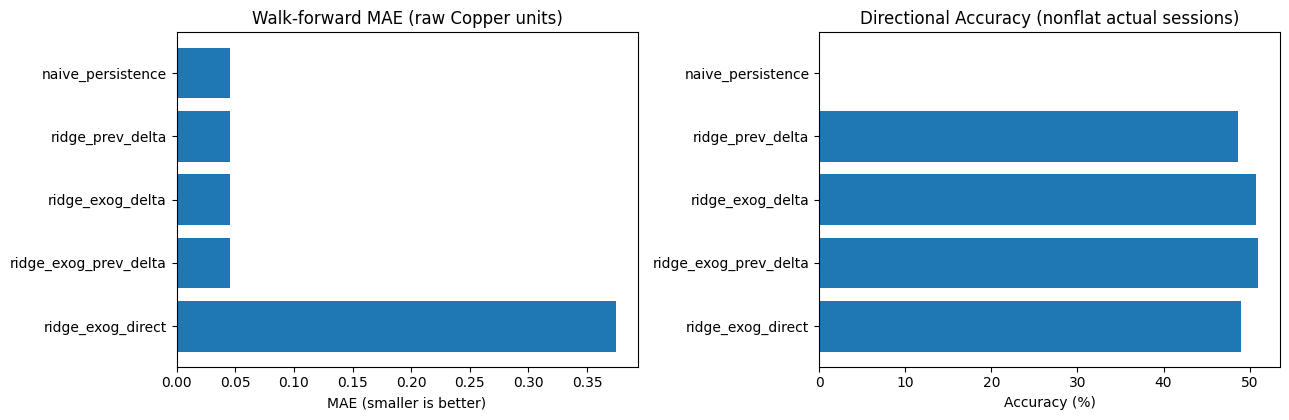

In [17]:
display(summary[['model','MAE_raw','RMSE_raw','DA_nonflat_%',
                 'MAE_improvement_over_naive_%']])
fig,axes=plt.subplots(1,2,figsize=(13,4.3))
axes[0].barh(summary.model[::-1],summary.MAE_raw[::-1]);axes[0].set_title('Walk-forward MAE (raw Copper units)')
axes[0].set_xlabel('MAE (smaller is better)')
axes[1].barh(summary.model[::-1],summary['DA_nonflat_%'][::-1]);axes[1].set_title('Directional Accuracy (nonflat actual sessions)')
axes[1].set_xlabel('Accuracy (%)')
fig.tight_layout();fig.savefig(OUT/'ablation_mae_da.png',dpi=160,bbox_inches='tight');plt.show()

## 8. Actual vs Predicted và sai số theo thời gian

Biểu đồ dưới đây được tạo sau khi train. Đường gần giá thực tế chỉ có ý nghĩa nếu **MAE, RMSE, DA và kiểm định DM** cũng đạt yêu cầu; Persistence luôn có thể bám sát mức giá mà không dự đoán hướng biến động.

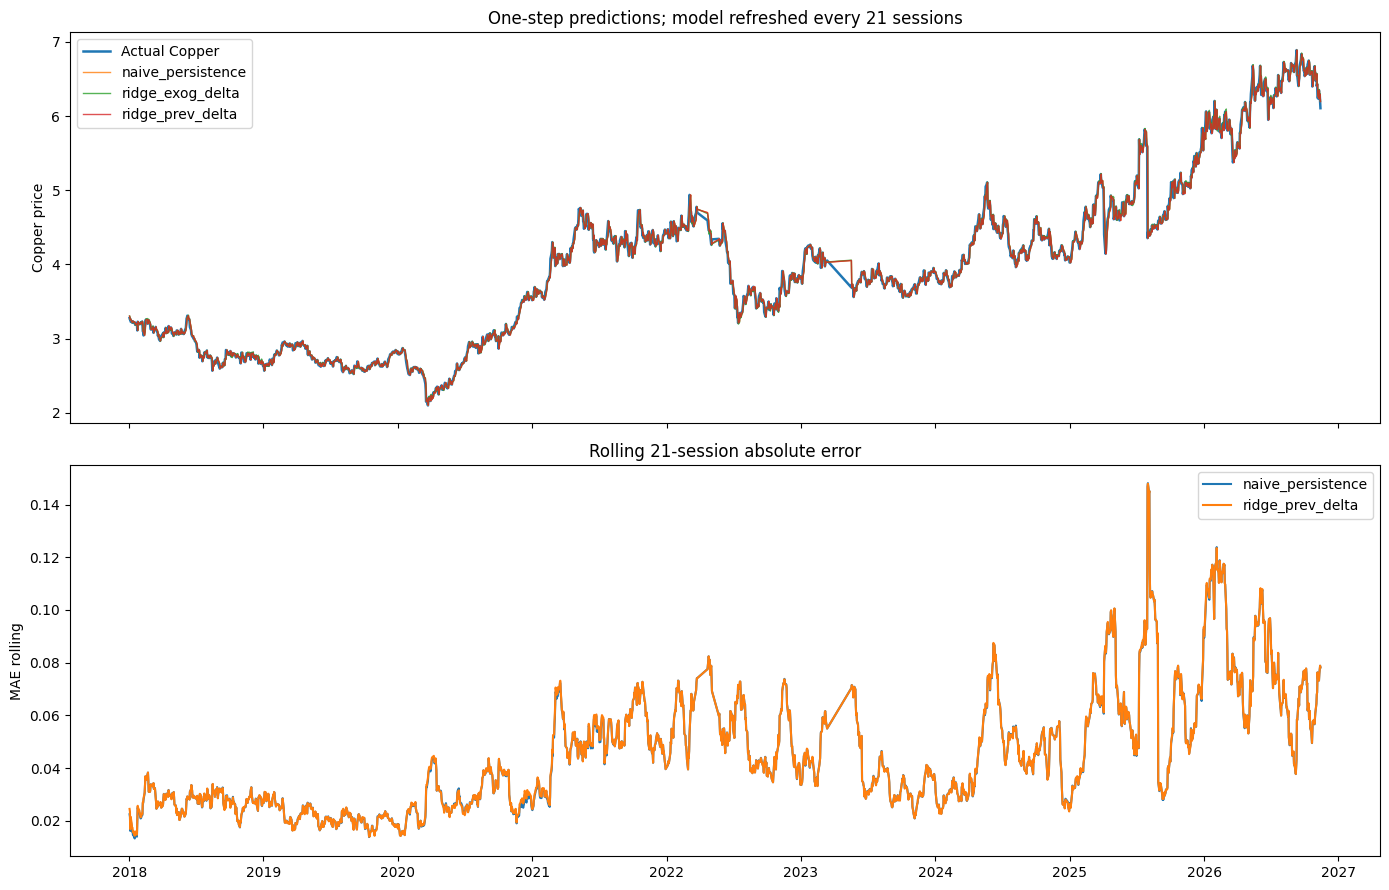

In [18]:
plot_wide=wide_pred.copy()
actual_series=wide_true['naive_persistence']
best_model=summary[summary.model!='naive_persistence'].iloc[0].model
fig,axes=plt.subplots(2,1,figsize=(14,9),sharex=True)
axes[0].plot(actual_series.index,actual_series.values,label='Actual Copper',lw=1.8)
for model in ['naive_persistence','ridge_exog_delta',best_model]:
    axes[0].plot(plot_wide.index,plot_wide[model].values,label=model,lw=1,alpha=.8)
axes[0].legend();axes[0].set_title('One-step predictions; model refreshed every 21 sessions')
axes[0].set_ylabel('Copper price')
for model in ['naive_persistence',best_model]:
    e=np.abs(actual_series.values-plot_wide[model].values)
    axes[1].plot(plot_wide.index,pd.Series(e,index=plot_wide.index).rolling(21,min_periods=1).mean(),label=model)
axes[1].set_title('Rolling 21-session absolute error')
axes[1].set_ylabel('MAE rolling');axes[1].legend()
fig.tight_layout();fig.savefig(OUT/'actual_predicted_and_error.png',dpi=160,bbox_inches='tight');plt.show()

## 9. Kiểm tra độ ổn định theo năm

Nếu mô hình chỉ thắng trong một vài năm mà thua nhiều năm khác, không nên gọi là phương pháp tốt ổn định. Tính MAE theo năm với **cùng các ngày backtest**.

model,naive_persistence,ridge_exog_delta,ridge_exog_direct,ridge_exog_prev_delta,ridge_prev_delta
year,,,,,
2018,0.027502,0.028264,0.343569,0.028473,0.027555
2019,0.020981,0.020707,0.172919,0.020726,0.020939
2020,0.028821,0.029529,0.266205,0.029686,0.029035
2021,0.051279,0.051334,0.342606,0.051378,0.051590
2022,0.053411,0.053789,0.402055,0.053851,0.053376
2023,0.038494,0.038709,0.233732,0.038707,0.038454
2024,0.044262,0.044305,0.231616,0.044337,0.044234
2025,0.067759,0.067822,0.479960,0.067591,0.067949
2026,0.078036,0.078406,0.953985,0.078387,0.078069


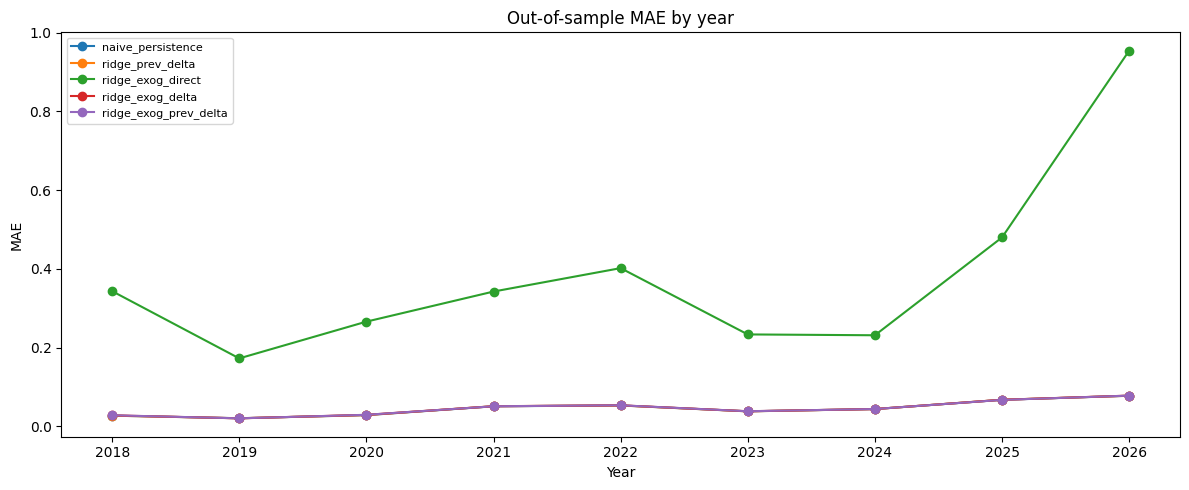

In [19]:
annual=predictions.copy()
annual['year']=annual.Date.dt.year
annual['abs_error']=(annual.actual-annual.prediction).abs()
annual_summary=annual.groupby(['year','model'],as_index=False).agg(MAE=('abs_error','mean'),n=('abs_error','size'))
annual_summary.to_csv(OUT/'annual_results.csv',index=False)
display(annual_summary.pivot(index='year',columns='model',values='MAE'))
fig,ax=plt.subplots(figsize=(12,5))
for model in MODEL_NAMES:
    ss=annual_summary[annual_summary.model==model]
    ax.plot(ss.year,ss.MAE,marker='o',label=model)
ax.set_title('Out-of-sample MAE by year');ax.set_xlabel('Year');ax.set_ylabel('MAE');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'annual_mae.png',dpi=160,bbox_inches='tight');plt.show()

## 10. Báo cáo tự động và ZIP Output

Thí nghiệm này kiểm tra **Ridge + Persistence**, không kiểm tra lại SA-LSTM. Số liệu được sinh từ quá trình Run All, không có kết quả giả định.

In [20]:
config_export={**CONFIG,'source_file':str(DATA_PATH), 'start_data':str(frame.Date.min().date()),
               'end_data':str(frame.Date.max().date()),'n_fold':int(len(folds)),
               'n_test_days':int(folds.n_test.sum()), 'sklearn':sklearn.__version__, 'scipy':scipy.__version__}
(OUT/'run_config.json').write_text(json.dumps(config_export,indent=2,ensure_ascii=False),encoding='utf-8')
winner=summary.iloc[0]
lines=['# Copper Residual Ridge — Walk-forward Backtesting',
       f'- Data source: `{DATA_PATH}`',
       f'- Data range: {frame.Date.min().date()} – {frame.Date.max().date()}',
       f'- Test range: {predictions.Date.min().date()} – {predictions.Date.max().date()}',
       f'- Training strategy: {CONFIG["training_policy"]}; refit each {CONFIG["retrain_every_sessions"]} sessions.',
       '- Information available at t−1 only; one-step forecast Copper(t).',
       f'- Best model by backtest MAE (descriptive, NOT test-based selection for future deployment): {winner.model}',
       f'- Best MAE: {winner.MAE_raw:.6f}, RMSE: {winner.RMSE_raw:.6f}',
       '- Model hyperparameters were tuned only on historical validation blocks.',
       '- Caveat: model ranking over the same backtest period introduces selection bias for claims about a deployed champion.',
       '- DM-style HAC p-values are exploratory and corrected with Holm across 4 comparisons.',
       '- No evidence of economic profitability is claimed from MAE/DA alone.']
(OUT/'research_summary.md').write_text('\n'.join(lines),encoding='utf-8')
zip_path=OUT.parent / 'copper_residual_ridge_4_tests_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.rglob('*')):
        if f.is_file(): z.write(f,arcname=str(OUT.name+'/'+str(f.relative_to(OUT))))
print('Saved:',zip_path,'| files:',len(list(OUT.iterdir())))

Saved: /kaggle/working/copper_residual_ridge_4_tests_results.zip | files: 12
